# 실험 1 샘플링 — 기준 (노이즈 없는 PennyLane)

실험 1(5x5, 인스턴스 0, c = 0.1)에서 학습해 둔 파라미터로, 아래 5개 시점의 회로를 각각 512 shots 샘플링한다. 학습은 하지 않는다.

| 시점 | θ | 회로 |
|---|---|---|
| ① 초기 | 상수 초기값 θ_init (두 방식 공통) | 전체 회로 (각도 366개) |
| ② exact-only 20 step 후 | exact-only 최종 θ | 전체 회로 |
| ③ SAFE 사전학습 직후 (증류 전) | LWPP 200 step 직후 θ | 전체 회로 |
| ④ SAFE 증류 직후 | 증류 후 θ (exact step 0) | 증류 후 회로 |
| ⑤ SAFE fine-tuning 후 | exact 20 step 후 θ | 증류 후 회로 |

이 노트북이 하는 일:
1. 실험 1 결과에서 5개 시점을 꺼내 `points.json`으로 저장한다(모든 backend가 같은 입력을 쓴다). H2 노트북(`sample_h2.ipynb`)도 이 파일을 읽는다.
2. 노이즈 없는 샘플링: PennyLane `lightning.amdgpu` (AMD GPU, 수 초).
3. 모든 backend 결과(노이즈 없는 기준, H2 실기기)를 모아 그림과 `summary.json`을 만든다.

결과는 모두 `results_on_MI300X/extras/sampling_h2/grid5x5_inst0_seed120490/` 한 곳에 backend별 하위 폴더로 저장된다. 비트열은 모든 backend에서 **q번째 문자 = 큐비트 q**로 통일한다(`problems/*.json`의 `ground_state_bits`와 같은 규약). 이미 저장된 결과는 다시 돌리지 않는다.

## 설정

In [1]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pennylane as qml

from common import save_json   # extras/sampling_h2/common.py

CASE = "grid5x5_inst0_seed120490"
C_INIT = 0.1                  # 실험 1의 상수 초기화 c (γ = +c, β = −c)
SHOTS = 512                   # 시점 하나당 샘플 수
SEED = 1234                   # 노이즈 없는 샘플링의 난수 seed
EXACT_DEVICE = "lightning.amdgpu"

REPO = Path.cwd().parents[1]      # 이 노트북은 extras/sampling_h2/ 폴더에서 실행한다
EXP1 = REPO / "results_on_MI300X" / "TC1" / CASE
OUT = REPO / "results_on_MI300X" / "extras" / "sampling_h2" / CASE
OUT.mkdir(parents=True, exist_ok=True)

## 1. 5개 시점 (`points.json`)

실험 1의 `standard/params.json`, `pado_safe/params.json`에서 c = 0.1인 초기값의 기록을 꺼낸다. 증류 후 회로는 실험 1 `safe.py`와 같은 규칙으로 다시 만든다: 남은 각도(`active_params`)의 게이트만 두고 번호를 0부터 다시 매긴다. 각 시점에는 실험 1이 계산해 둔 노이즈 없는 기댓값 에너지와 AR도 함께 적는다. 파일이 이미 있으면 새로 만든 내용과 같은지만 확인한다.

In [2]:
prob = json.loads((REPO / "problems" / f"{CASE}.json").read_text())
n, e_min, e_max = prob["n_qubits"], prob["e_min"], prob["e_max"]
ar = lambda e: (e_max - e) / (e_max - e_min)

A = [r for r in json.loads((EXP1 / "standard" / "params.json").read_text())["inits"] if r["c"] == C_INIT][0]
B = [r for r in json.loads((EXP1 / "pado_safe" / "params.json").read_text())["inits"] if r["c"] == C_INIT][0]
assert A["theta_init"] == B["theta_init"]            # 두 방식은 같은 초기값에서 시작
full_gates = json.loads((EXP1 / "pado_safe" / "circuit.json").read_text())["gates"]

# 증류 후 회로: 남은 각도의 게이트만, 번호는 남은 순서대로 0..N_active-1
new_idx = {old: new for new, old in enumerate(B["active_params"])}
pruned_gates = [g for g in full_gates if g["gate"] == "H"]
for g in full_gates[n:]:
    if g["param"] in new_idx:
        pruned_gates.append({"gate": g["gate"], "wires": g["wires"], "param": new_idx[g["param"]]})

points = {
    "p1_initial":         {"label": "1 initial", "gates": full_gates, "theta": A["theta_init"], "energy_exact": A["energy"][0]},
    "p2_exact_only":      {"label": "2 exact-only\n20 steps", "gates": full_gates, "theta": A["theta_final"], "energy_exact": A["energy"][-1]},
    "p3_safe_pretrained": {"label": "3 SAFE\npretrained", "gates": full_gates, "theta": B["theta_lwpp_final"], "energy_exact": B["exact_energy_lwpp_final"]},
    "p4_safe_distilled":  {"label": "4 SAFE\ndistilled", "gates": pruned_gates, "theta": B["theta_traj_active"][0], "energy_exact": B["energy"][0]},
    "p5_safe_finetuned":  {"label": "5 SAFE\nfine-tuned 20 steps", "gates": pruned_gates, "theta": B["theta_traj_active"][-1], "energy_exact": B["energy"][-1]},
}
for p in points.values():
    p["ar_exact"] = ar(p["energy_exact"])
    p["n_params"] = len(p["theta"])
    p["n_rzz"] = sum(g["gate"] == "RZZ" for g in p["gates"])
points_doc = {"case": CASE, "c": C_INIT, "shots": SHOTS, "e_min": e_min, "e_max": e_max,
              "convention": "R_P(theta) = exp(-i theta P / 2); bitstring character q = qubit q; initial state |0..0>",
              "points": points}
if (OUT / "points.json").exists():
    assert json.loads((OUT / "points.json").read_text()) == json.loads(json.dumps(points_doc)), "points.json differs from exp1"
else:
    save_json(OUT / "points.json", points_doc)
for key, p in points.items():
    print(f"{key:20s} angles={p['n_params']:3d}  RZZ gates={p['n_rzz']:3d}  exact AR={p['ar_exact']:.4f}")

p1_initial           angles=366  RZZ gates=216  exact AR=0.5081
p2_exact_only        angles=366  RZZ gates=216  exact AR=0.8101
p3_safe_pretrained   angles=366  RZZ gates=216  exact AR=0.8416
p4_safe_distilled    angles=162  RZZ gates= 72  exact AR=0.9475
p5_safe_finetuned    angles=162  RZZ gates= 72  exact AR=0.9663


확인: 각 시점의 노이즈 없는 기댓값을 PennyLane으로 다시 계산해 실험 1의 값과 같은지 본다(시점 정의가 맞는지 확인).

In [3]:
H = qml.Hamiltonian([w for _, _, w in prob["edges"]] + [h for _, h in prob["fields"]],
                    [qml.Z(u) @ qml.Z(v) for u, v, _ in prob["edges"]] + [qml.Z(q) for q, _ in prob["fields"]])
dev = qml.device(EXACT_DEVICE, wires=n)


@qml.qnode(dev)
def energy(theta, gates):
    for g in gates:
        if g["gate"] == "H":
            qml.Hadamard(g["wires"][0])
        elif g["gate"] == "RZZ":
            qml.IsingZZ(theta[g["param"]], wires=g["wires"])
        elif g["gate"] == "RZ":
            qml.RZ(theta[g["param"]], wires=g["wires"][0])
        elif g["gate"] == "RX":
            qml.RX(theta[g["param"]], wires=g["wires"][0])
    return qml.expval(H)


for key, p in points.items():
    e = float(energy(np.array(p["theta"]), p["gates"]))
    assert abs(e - p["energy_exact"]) < 1e-8, (key, e, p["energy_exact"])
    print(f"{key:20s} E = {e:+.8f}  (exp1: {p['energy_exact']:+.8f})")

p1_initial           E = -0.65781594  (exp1: -0.65781594)
p2_exact_only        E = -18.76776090  (exp1: -18.76776090)


p3_safe_pretrained   E = -20.65273560  (exp1: -20.65273560)
p4_safe_distilled    E = -27.00214059  (exp1: -27.00214059)
p5_safe_finetuned    E = -28.13099971  (exp1: -28.13099971)


## 2. 노이즈 없는 샘플링 (PennyLane `lightning.amdgpu`)

`qml.counts()`의 비트열은 0번 wire가 맨 왼쪽 글자라 우리 규약(q번째 문자 = 큐비트 q)과 같다. 확인으로, 샘플 평균 에너지가 기댓값과 통계 오차(표준편차/√shots) 안에서 맞는지 본다. 비트 순서가 틀리면 여기서 크게 어긋난다.

In [4]:
path = OUT / "noiseless" / "counts.json"
if path.exists():
    print("noiseless counts found, not sampled again")
else:
    dev_s = qml.device(EXACT_DEVICE, wires=n, seed=SEED)

    @qml.set_shots(SHOTS)
    @qml.qnode(dev_s)
    def sample(theta, gates):
        for g in gates:
            if g["gate"] == "H":
                qml.Hadamard(g["wires"][0])
            elif g["gate"] == "RZZ":
                qml.IsingZZ(theta[g["param"]], wires=g["wires"])
            elif g["gate"] == "RZ":
                qml.RZ(theta[g["param"]], wires=g["wires"][0])
            elif g["gate"] == "RX":
                qml.RX(theta[g["param"]], wires=g["wires"][0])
        return qml.counts()

    data = {"backend": f"noiseless statevector sampling, PennyLane {EXACT_DEVICE}", "shots": SHOTS, "seed": SEED, "counts": {}}
    for key, p in points.items():
        t0 = time.perf_counter()
        counts = sample(np.array(p["theta"]), p["gates"])
        data["counts"][key] = {str(b): int(c) for b, c in counts.items()}
        print(f"{key:20s} {len(counts)} distinct bitstrings  {time.perf_counter() - t0:.1f}s")
    (OUT / "noiseless").mkdir(exist_ok=True)
    save_json(path, data)

# 확인: 샘플 평균 에너지 vs 기댓값
data = json.loads(path.read_text())
for key, p in points.items():
    counts = data["counts"][key]
    bits = np.array([[int(ch) for ch in s] for s in counts]); mult = np.array(list(counts.values()))
    s = 1 - 2 * bits
    e = sum(w * s[:, u] * s[:, v] for u, v, w in prob["edges"]) + sum(h * s[:, q] for q, h in prob["fields"])
    mean = (e * mult).sum() / mult.sum(); std = np.sqrt((((e - mean) ** 2) * mult).sum() / mult.sum())
    z = (mean - p["energy_exact"]) / (std / np.sqrt(mult.sum()))
    print(f"{key:20s} sample mean {mean:+.3f}  exact {p['energy_exact']:+.3f}  z = {z:+.2f}")
    assert abs(z) < 5, 'sample mean far from the exact expectation: check the bit order'

noiseless counts found, not sampled again
p1_initial           sample mean -0.467  exact -0.658  z = +0.68
p2_exact_only        sample mean -18.589  exact -18.768  z = +0.79
p3_safe_pretrained   sample mean -20.861  exact -20.653  z = -1.10
p4_safe_distilled    sample mean -27.088  exact -27.002  z = -0.80
p5_safe_finetuned    sample mean -28.146  exact -28.131  z = -1.13


## 모든 backend 결과 모으기와 그림

`OUT` 아래에서 `counts.json`이 있는 하위 폴더(= backend)를 모두 읽는다. 지금까지 모인 backend만 그림에 들어가므로, 어느 노트북을 나중에 돌려도 그림과 `summary.json`이 다시 만들어진다. backend별 원본 counts는 건드리지 않는다.

- 샘플 하나의 에너지: 비트열에서 s_q = 1 − 2·bit_q, E = Σ J_ij s_i s_j + Σ h_i s_i
- 샘플 AR = (E_max − 샘플 평균 에너지) / (E_max − E_min), brute force E_min, E_max는 `problems/<케이스>.json`
- 바닥 상태 비율 = brute force 바닥 상태 비트열이 나온 횟수 / shots
- `sampling_hist.png`: backend별 한 줄, 왼쪽은 exact-only 경로(①②), 오른쪽은 SAFE 경로(①③④⑤)의 샘플 에너지 분포. 파란 점선은 E_min
- `sampling_ar.png`: 시점별 AR 막대. 회색은 실험 1의 노이즈 없는 기댓값, 나머지는 backend별 샘플 AR

noiseless        p1_initial           AR sampled=0.5049 (exact 0.5081)  best E=-18.981  P(ground)=0.0000
noiseless        p2_exact_only        AR sampled=0.8071 (exact 0.8101)  best E=-29.777  P(ground)=0.0000
noiseless        p3_safe_pretrained   AR sampled=0.8450 (exact 0.8416)  best E=-28.165  P(ground)=0.0000
noiseless        p4_safe_distilled    AR sampled=0.9489 (exact 0.9475)  best E=-28.165  P(ground)=0.0000
noiseless        p5_safe_finetuned    AR sampled=0.9665 (exact 0.9663)  best E=-28.165  P(ground)=0.0000


saved results_on_MI300X/extras/sampling_h2/grid5x5_inst0_seed120490/sampling_hist.png and results_on_MI300X/extras/sampling_h2/grid5x5_inst0_seed120490/sampling_ar.png


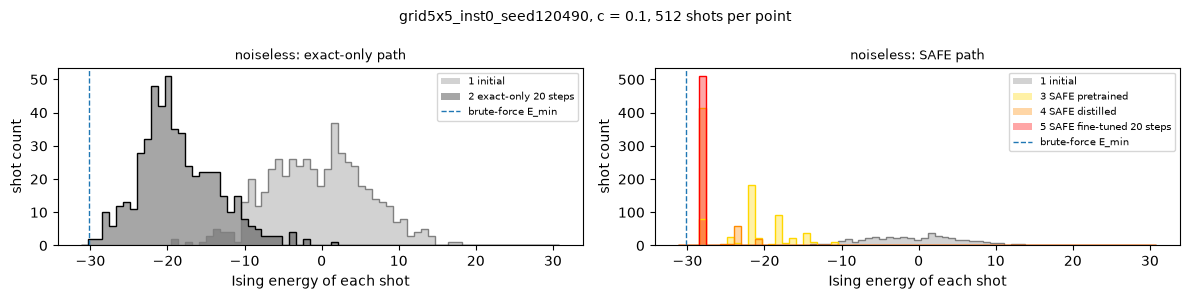

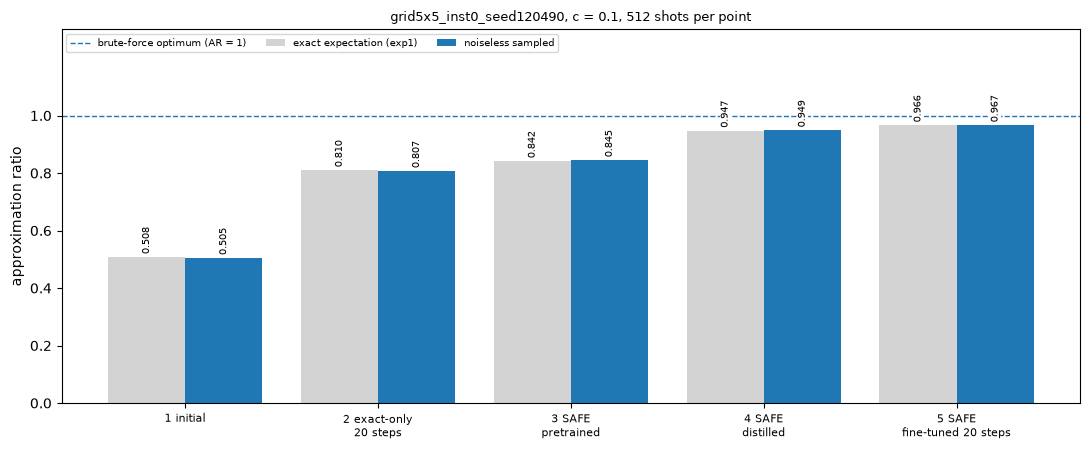

In [5]:
points_doc = json.loads((OUT / "points.json").read_text())
points = points_doc["points"]
prob = json.loads((REPO / "problems" / f"{CASE}.json").read_text())
n, e_min, e_max = prob["n_qubits"], prob["e_min"], prob["e_max"]
ground = "".join(str(b) for b in prob["ground_state_bits"])          # 문자 q = 큐비트 q
U = np.array([u for u, _, _ in prob["edges"]]); V = np.array([v for _, v, _ in prob["edges"]])
W = np.array([w for _, _, w in prob["edges"]])
Q = np.array([q for q, _ in prob["fields"]]); HF = np.array([h for _, h in prob["fields"]])

# backend 폴더 순서: 노이즈 없는 기준, 그 밖(H2 기기 등)
found = sorted(d.name for d in OUT.iterdir() if (d / "counts.json").exists())
backends = [b for b in ["noiseless"] if b in found] + [b for b in found if b != "noiseless"]
colors = {"noiseless": "tab:blue"}
extra = iter(["tab:red", "tab:purple", "tab:brown", "tab:green"])
for b in backends:
    colors.setdefault(b, next(extra))

# 샘플별 에너지와 요약
energies, summary = {}, {"case": CASE, "c": points_doc["c"], "e_min": e_min, "e_max": e_max, "backends": {}}
for b in backends:
    data = json.loads((OUT / b / "counts.json").read_text())
    energies[b], summary["backends"][b] = {}, {}
    for key, counts in data["counts"].items():
        bits = np.array([[int(ch) for ch in s] for s in counts])            # (서로 다른 비트열 수, n)
        mult = np.array(list(counts.values()))                              # 각 비트열이 나온 횟수
        s = 1 - 2 * bits
        e = (s[:, U] * s[:, V]) @ W + s[:, Q] @ HF                           # 비트열별 에너지
        energies[b][key] = (e, mult)
        shots = int(mult.sum())
        mean = float((e * mult).sum() / shots)
        summary["backends"][b][key] = {
            "shots": shots, "mean_energy": mean,
            "std_energy": float(np.sqrt((((e - mean) ** 2) * mult).sum() / shots)),
            "ar_sampled": (e_max - mean) / (e_max - e_min),
            "best_energy": float(e.min()), "best_ar": (e_max - float(e.min())) / (e_max - e_min),
            "p_ground_state": counts.get(ground, 0) / shots,
            "ar_exact_expectation": points[key]["ar_exact"]}
save_json(OUT / "summary.json", summary)
for b in backends:
    for key in points:
        if key in summary["backends"][b]:
            r = summary["backends"][b][key]
            print(f"{b:16s} {key:20s} AR sampled={r['ar_sampled']:.4f} (exact {r['ar_exact_expectation']:.4f})  "
                  f"best E={r['best_energy']:+.3f}  P(ground)={r['p_ground_state']:.4f}")

# 그림 1: 샘플 에너지 분포
paths = [("exact-only path", ["p1_initial", "p2_exact_only"]),
         ("SAFE path", ["p1_initial", "p3_safe_pretrained", "p4_safe_distilled", "p5_safe_finetuned"])]
point_colors = {"p1_initial": "gray", "p2_exact_only": "black", "p3_safe_pretrained": "gold",
                "p4_safe_distilled": "darkorange", "p5_safe_finetuned": "red"}
bins = np.linspace(e_min - 1, e_max + 1, 70)
fig, axes = plt.subplots(len(backends), 2, figsize=(12, 3.0 * len(backends)), squeeze=False, sharex=True)
for row, b in enumerate(backends):
    for col, (title, keys) in enumerate(paths):
        ax = axes[row][col]
        for key in keys:
            if key in energies[b]:
                e, mult = energies[b][key]
                ax.hist(e, bins=bins, weights=mult, histtype="stepfilled", alpha=0.35, color=point_colors[key],
                        label=points[key]["label"].replace("\n", " "))
                ax.hist(e, bins=bins, weights=mult, histtype="step", color=point_colors[key])
        ax.axvline(e_min, color="tab:blue", linestyle="--", linewidth=1, label="brute-force E_min")
        ax.set_title(f"{b}: {title}", fontsize=9)
        ax.set_ylabel("shot count")
        ax.legend(fontsize=7)
for ax in axes[-1]:
    ax.set_xlabel("Ising energy of each shot")
fig.suptitle(f"{CASE}, c = {points_doc['c']}, {points_doc['shots']} shots per point", fontsize=10)
fig.tight_layout()
fig.savefig(OUT / "sampling_hist.png", dpi=150)

# 그림 2: 시점별 AR 막대 (회색 = 실험 1 노이즈 없는 기댓값)
keys = list(points)
series = [("exact expectation (exp1)", [points[k]["ar_exact"] for k in keys], "lightgray")]
series += [(f"{b} sampled", [summary["backends"][b].get(k, {}).get("ar_sampled", np.nan) for k in keys], colors[b]) for b in backends]
x = np.arange(len(keys))
width = 0.8 / len(series)
fig, ax = plt.subplots(figsize=(11, 4.6))
for i, (name, vals, color) in enumerate(series):
    xs = x - 0.4 + width * (i + 0.5)
    ax.bar(xs, vals, width, color=color, label=name)
    for xv, val in zip(xs, vals):
        if not np.isnan(val):
            ax.text(xv, val + 0.01, f"{val:.3f}", ha="center", va="bottom", fontsize=7, rotation=90,
                    bbox=dict(facecolor="white", edgecolor="none", pad=0.5), zorder=3)
ax.axhline(1.0, color="tab:blue", linestyle="--", linewidth=1, label="brute-force optimum (AR = 1)")
ax.set_xticks(x)
ax.set_xticklabels([points[k]["label"] for k in keys], fontsize=8)
ax.set_ylim(0, 1.3)
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.set_ylabel("approximation ratio")
ax.set_title(f"{CASE}, c = {points_doc['c']}, {points_doc['shots']} shots per point", fontsize=9)
ax.legend(fontsize=7, loc="upper left", ncol=len(series) + 1)
fig.tight_layout()
fig.savefig(OUT / "sampling_ar.png", dpi=150)
print("saved", (OUT / "sampling_hist.png").relative_to(REPO), "and", (OUT / "sampling_ar.png").relative_to(REPO))